In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [4]:
df = pd.read_csv("kolkata_weather_jan_june_2026.csv")
df.head()

,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [5]:
print("Jumlah baris  :", df.shape[0])
print("Jumlah kolom  :", df.shape[1])
print("Rentang tanggal:", df["time"].min(), "s/d", df["time"].max())
df.info()

Jumlah baris  : 1827
Jumlah kolom  : 17
Rentang tanggal: 2021-06-30 s/d 2026-06-30
<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   str    
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   str    
 12  suns

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
weather_code,1827.0,34.143952,2.899722e+01,0.0000,3.0000,51.0000,63.0000,65.0000
temperature_2m_mean,1827.0,26.264860,4.050220e+00,15.0000,23.4000,27.4000,29.1000,35.2000
temperature_2m_max,1827.0,31.099234,3.924558e+00,19.6000,28.7000,31.3000,33.3000,43.9000
temperature_2m_min,1827.0,22.477066,4.847343e+00,10.2000,18.6000,24.6000,26.2000,30.6000
precipitation_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
rain_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
precipitation_hours,1827.0,4.952928,6.275264e+00,0.0000,0.0000,2.0000,9.0000,24.0000
wind_speed_10m_max,1827.0,13.782157,5.106847e+00,4.5000,10.0000,12.6000,16.6000,44.0000
wind_gusts_10m_max,1827.0,30.756596,9.081119e+00,11.5000,24.1000,29.5000,36.0000,83.9000
wind_direction_10m_dominant,1827.0,192.212917,1.001658e+02,0.0000,135.0000,188.0000,258.0000,360.0000


In [7]:
# Target biner: weather_code >= 51 berarti hujan (standar WMO)
df["hujan"] = (df["weather_code"] >= 51).astype(int)

# Kolom yang dibuang agar tidak terjadi data leakage / tidak informatif
kolom_leakage   = ["weather_code", "precipitation_sum", "rain_sum", "precipitation_hours"]
kolom_konstan   = ["city", "latitude", "longitude"]
kolom_waktu_raw = ["sunrise", "sunset"]

print("Target (y)     : hujan")
print("Fitur mentah   :", [c for c in df.columns
                           if c not in kolom_leakage + kolom_konstan + kolom_waktu_raw + ["hujan"]])
print(df["hujan"].value_counts().rename({0: "Tidak Hujan", 1: "Hujan"}))

Target (y)     : hujan
Fitur mentah   : ['time', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration']
hujan
Hujan          1021
Tidak Hujan     806
Name: count, dtype: int64


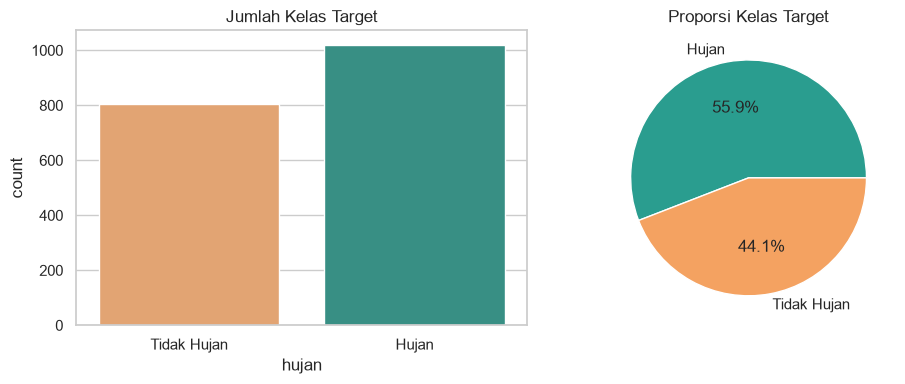

In [8]:
# Proporsi kelas target
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="hujan", data=df, palette=["#f4a261", "#2a9d8f"], ax=ax[0])
ax[0].set_xticklabels(["Tidak Hujan", "Hujan"])
ax[0].set_title("Jumlah Kelas Target")
df["hujan"].map({0: "Tidak Hujan", 1: "Hujan"}).value_counts().plot.pie(
    autopct="%1.1f%%", colors=["#2a9d8f", "#f4a261"], ax=ax[1])
ax[1].set_ylabel("")
ax[1].set_title("Proporsi Kelas Target")
plt.tight_layout()
plt.show()

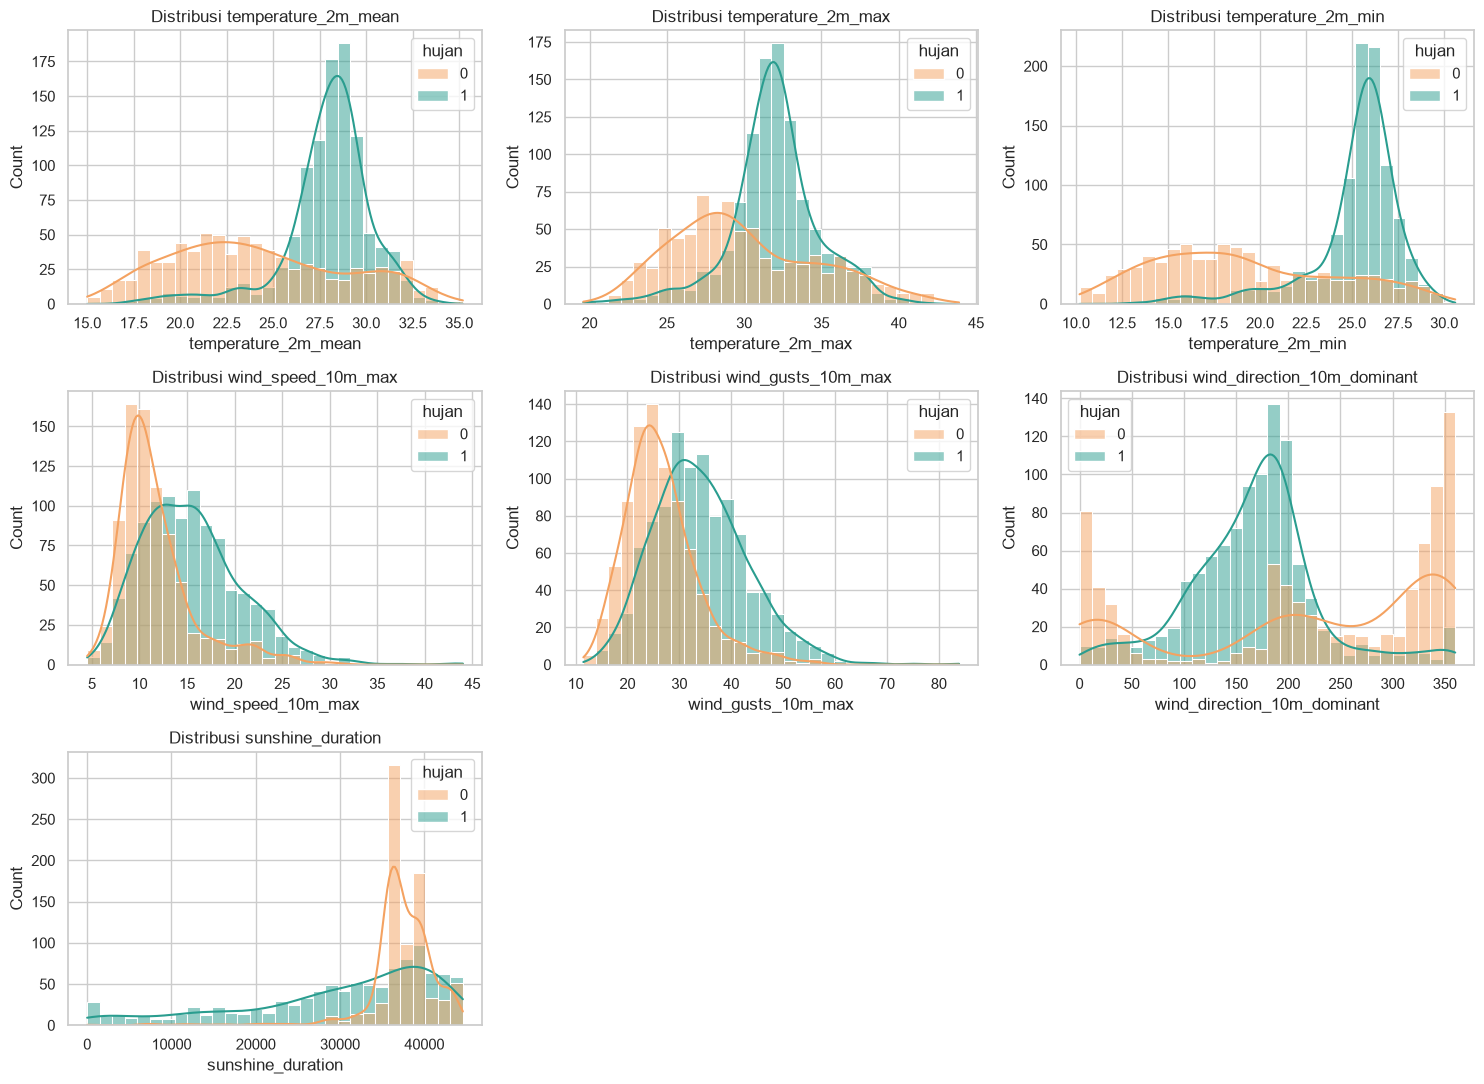

In [9]:
# Distribusi tiap fitur numerik
fitur_numerik = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
                 "wind_speed_10m_max", "wind_gusts_10m_max",
                 "wind_direction_10m_dominant", "sunshine_duration"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), fitur_numerik):
    sns.histplot(data=df, x=col, hue="hujan", kde=True, bins=30,
                 palette=["#f4a261", "#2a9d8f"], ax=ax)
    ax.set_title(f"Distribusi {col}")
for ax in axes.ravel()[len(fitur_numerik):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
# Missing values
missing = df.isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing values.")
print("Duplikat baris:", df.duplicated().sum())

Tidak ada missing values.
Duplikat baris: 0


In [11]:
# Pengaman imputasi (tidak berpengaruh jika tidak ada missing values)
for col in df.select_dtypes(include="number").columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(exclude="number").columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])
print("Sisa missing values:", df.isna().sum().sum())

Sisa missing values: 0


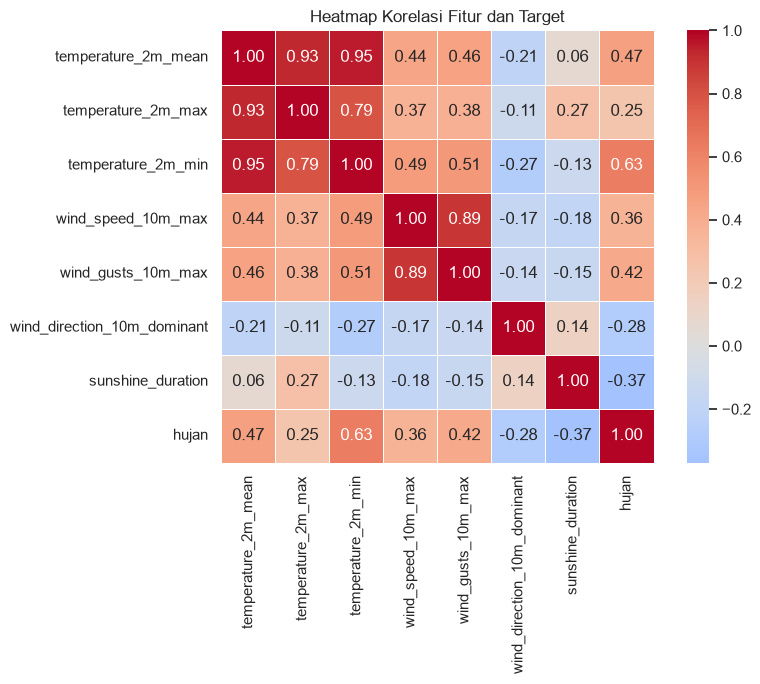

In [12]:
# Heatmap korelasi
plt.figure(figsize=(9, 7))
sns.heatmap(df[fitur_numerik + ["hujan"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Heatmap Korelasi Fitur dan Target")
plt.tight_layout()
plt.show()

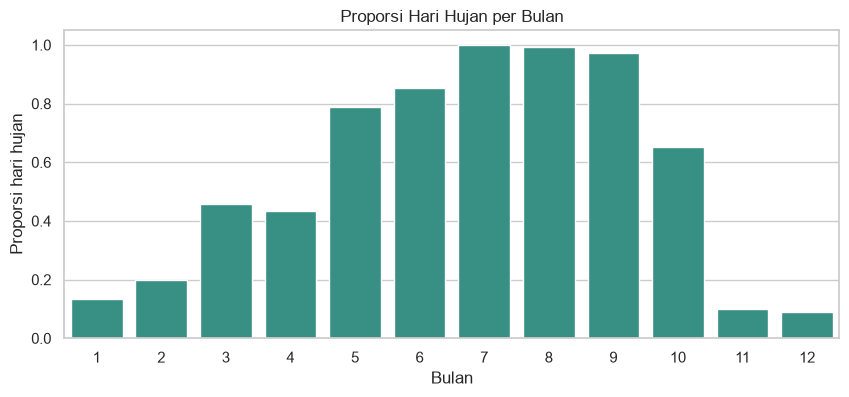

In [13]:
# Pola musiman
df["time"] = pd.to_datetime(df["time"])
df["bulan"] = df["time"].dt.month

plt.figure(figsize=(10, 4))
sns.barplot(x="bulan", y="hujan", data=df, color="#2a9d8f", errorbar=None)
plt.title("Proporsi Hari Hujan per Bulan")
plt.ylabel("Proporsi hari hujan")
plt.xlabel("Bulan")
plt.show()

In [14]:
def buat_musim(bulan):
    if bulan in (12, 1, 2):
        return "Dingin"
    elif bulan in (3, 4, 5):
        return "Pra-Monsun"
    elif bulan in (6, 7, 8, 9):
        return "Monsun"
    return "Pasca-Monsun"

df["musim"] = df["bulan"].apply(buat_musim)

In [15]:
# Pilih fitur (tanpa kolom leakage) lalu one-hot encoding untuk 'musim'
fitur_dipakai = fitur_numerik + ["bulan", "musim"]
X = pd.get_dummies(df[fitur_dipakai], columns=["musim"], dtype=int)

# Target: 0 = Tidak Hujan, 1 = Hujan
# (LabelEncoder tidak dipakai karena mengurutkan alfabetis sehingga "Hujan" jadi 0)
y = df["hujan"].values
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)
X.head()

Bentuk X: (1827, 12) | Bentuk y: (1827,)


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,bulan,musim_Dingin,musim_Monsun,musim_Pasca-Monsun,musim_Pra-Monsun
0,29.9,33.4,28.0,23.7,46.1,206,20837.76,6,0,1,0,0
1,29.8,33.4,27.8,19.1,37.1,193,21439.24,7,0,1,0,0
2,29.2,32.2,27.8,18.7,33.8,209,12291.52,7,0,1,0,0
3,29.2,32.9,27.3,15.5,32.0,202,29486.65,7,0,1,0,0
4,28.6,32.1,26.9,12.0,29.5,180,41145.46,7,0,1,0,0


In [16]:
# Split 80% latih : 20% uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)

Data latih : (1461, 12)
Data uji   : (366, 12)


In [17]:
# Cek data leakage
terlarang = set(kolom_leakage + ["hujan"])
bocor = terlarang.intersection(X.columns)
assert len(bocor) == 0, f"Ada kolom bocor di fitur: {bocor}"
assert len(set(X_train.index) & set(X_test.index)) == 0, "Data latih dan uji beririsan!"
print("Aman: tidak ada data leakage.")
print("Fitur akhir:", list(X.columns))

Aman: tidak ada data leakage.
Fitur akhir: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration', 'bulan', 'musim_Dingin', 'musim_Monsun', 'musim_Pasca-Monsun', 'musim_Pra-Monsun']


In [18]:
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [19]:
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

pd.DataFrame({"Aktual": y_test, "Prediksi": y_pred,
              "Prob_Hujan": y_proba.round(3)}).head(10)

,Aktual,Prediksi,Prob_Hujan
0,1,0,0.404
1,1,1,0.999
2,0,0,0.003
3,1,1,0.999
4,1,1,0.999
5,0,1,0.841
6,1,1,0.998
7,1,1,0.999
8,1,1,0.999
9,0,0,0.468


In [20]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_proba)

metrik = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Nilai":  [acc, prec, rec, f1, auc]
}).round(4)
metrik

,Metrik,Nilai
0,Accuracy,0.8689
1,Precision,0.8867
2,Recall,0.8780
3,F1-Score,0.8824
4,ROC-AUC,0.9475


In [21]:
print(classification_report(y_test, y_pred, target_names=["Tidak Hujan", "Hujan"]))

              precision    recall  f1-score   support

 Tidak Hujan       0.85      0.86      0.85       161
       Hujan       0.89      0.88      0.88       205

    accuracy                           0.87       366
   macro avg       0.87      0.87      0.87       366
weighted avg       0.87      0.87      0.87       366



In [22]:
def label(x):
    return "sangat baik" if x >= 0.9 else "baik" if x >= 0.8 else "cukup" if x >= 0.7 else "kurang"

print(f"- Akurasi {acc:.2%}: model mengklasifikasikan {label(acc)}.")
print(f"- Precision {prec:.2%}: dari semua hari yang diprediksi hujan, {prec:.2%} benar-benar hujan.")
print(f"- Recall {rec:.2%}: dari semua hari yang benar-benar hujan, {rec:.2%} terdeteksi.")
print(f"- F1-Score {f1:.2%}: keseimbangan precision dan recall tergolong {label(f1)}.")
print(f"- ROC-AUC {auc:.3f}: kemampuan membedakan kelas tergolong {label(auc)}.")

- Akurasi 86.89%: model mengklasifikasikan baik.
- Precision 88.67%: dari semua hari yang diprediksi hujan, 88.67% benar-benar hujan.
- Recall 87.80%: dari semua hari yang benar-benar hujan, 87.80% terdeteksi.
- F1-Score 88.24%: keseimbangan precision dan recall tergolong baik.
- ROC-AUC 0.947: kemampuan membedakan kelas tergolong sangat baik.


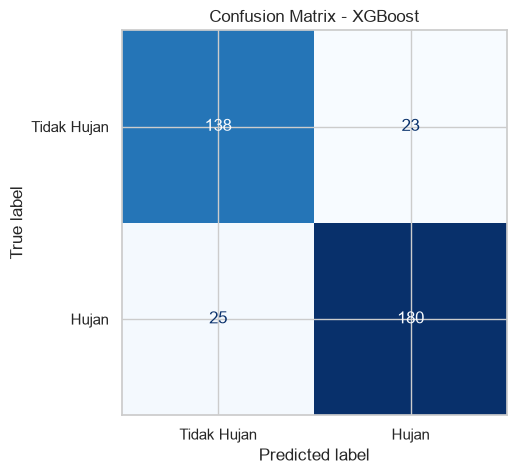

In [23]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=["Tidak Hujan", "Hujan"]).plot(
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix - XGBoost")
plt.show()

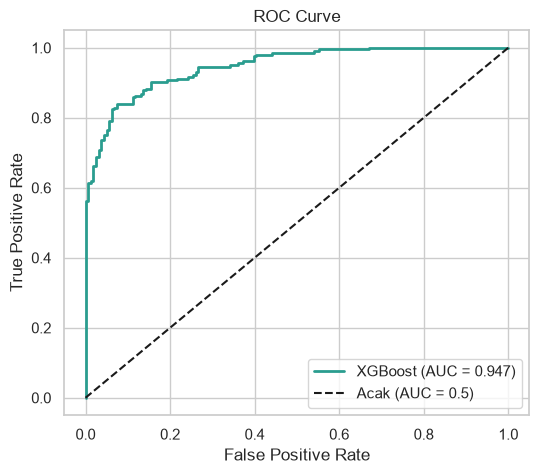

In [24]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#2a9d8f", lw=2, label=f"XGBoost (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Acak (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

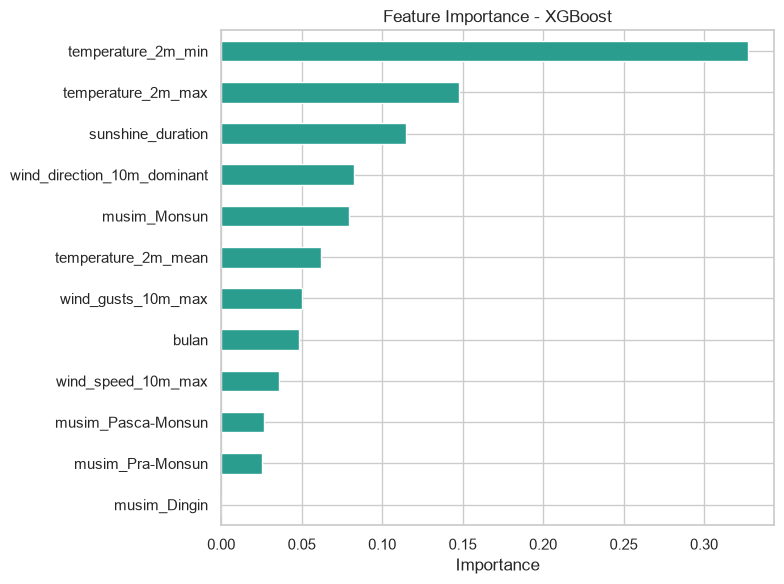

In [25]:
# Feature importance
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
plt.figure(figsize=(8, 6))
imp.plot.barh(color="#2a9d8f")
plt.title("Feature Importance - XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [26]:
# Simpan model dan metrik
joblib.dump({"model": model, "columns": list(X.columns)}, "model_xgb.pkl")
metrik.to_csv("metrik_evaluasi.csv", index=False)
